# RT-IoT2022 - Final Model Comparison

In this last notebook we will compare the three models previously tested. No model is trained here; the final results are loaded from the files saved by the previous notebooks, so the numbers are exactly the same.

All models were trained on the same normal traffic, tuned on the same validation set and evaluated on the same test set (2403 normal and 52954 anomalous samples), so the comparison is fair.

We compare the models in four ways:

- overall metrics
- statistical significance of the differences
- false alarms on each normal device
- detection rate for each attack type

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

TABLES_DIR = Path("../results/tables")
FIGURES_DIR = Path("../results/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

model_files = [
    "one_class_svm_final_metrics.csv",
    "isolation_forest_final_metrics.csv",
    "autoencoder_final_metrics.csv"
]

all_results = pd.concat(
    [pd.read_csv(TABLES_DIR / file) for file in model_files],
    ignore_index=True
)

metric_columns = [
    "accuracy", "precision", "recall", "f1",
    "balanced_accuracy", "fpr", "roc_auc", "pr_auc"
]

comparison_results = all_results[["model"] + metric_columns] 
comparison_results

,model,accuracy,precision,recall,f1,balanced_accuracy,fpr,roc_auc,pr_auc
0,One-Class SVM,0.988095,0.997318,0.990218,0.993755,0.965771,0.058677,0.988331,0.999391
1,Isolation Forest,0.948209,0.997457,0.948276,0.972245,0.947505,0.053267,0.959372,0.994644
2,Autoencoder,0.983959,0.997649,0.985553,0.991564,0.967184,0.051186,0.992868,0.999650


### Which metrics matter

About 96% of the test set is anomalous traffic. For this reason:

- **Accuracy, Precision and PR-AUC** are very high for all models and are not informative: even a model that flags everything as an attack would get a high value.
- **Balanced Accuracy** is the main metric: It gives the same weight to normal and anomalous traffic.
- **Recall** shows how many attacks are detected
- **False Positive Rate** shows how much normal traffic is flagged as an attack, i.e. the false alarms. 

In [2]:
comparison_ranked = (
    comparison_results.sort_values(
        by = [
            "balanced_accuracy",
            "fpr",
            "recall"
        ],
        ascending = [
            False,
            True,
            False
        ]
    )
    .reset_index(drop = True)
)

comparison_ranked

,model,accuracy,precision,recall,f1,balanced_accuracy,fpr,roc_auc,pr_auc
0,Autoencoder,0.983959,0.997649,0.985553,0.991564,0.967184,0.051186,0.992868,0.999650
1,One-Class SVM,0.988095,0.997318,0.990218,0.993755,0.965771,0.058677,0.988331,0.999391
2,Isolation Forest,0.948209,0.997457,0.948276,0.972245,0.947505,0.053267,0.959372,0.994644


Ranked by Balanced Accuracy, the Autoencoder is first (0.967), very close to One-Class SVM (0.966) while the Isolation Forest is clearly behind (0.948).

In [3]:
confusion_comparison = all_results[["model", "tn", "fp", "fn", "tp"]].copy()
confusion_comparison

,model,tn,fp,fn,tp
0,One-Class SVM,2262,141,518,52436
1,Isolation Forest,2275,128,2739,50215
2,Autoencoder,2280,123,765,52189


In [4]:
confusion_comparison["normal_total"] = (
    confusion_comparison["tn"] 
    + confusion_comparison["fp"]
)

confusion_comparison["anomaly_total"] = (
    confusion_comparison["fn"]
    + confusion_comparison["tp"]
)

confusion_comparison["total"] = (
    confusion_comparison["normal_total"]
    + confusion_comparison["anomaly_total"]
)

confusion_comparison

,model,tn,fp,fn,tp,normal_total,anomaly_total,total
0,One-Class SVM,2262,141,518,52436,2403,52954,55357
1,Isolation Forest,2275,128,2739,50215,2403,52954,55357
2,Autoencoder,2280,123,765,52189,2403,52954,55357


The totals confirm that the three models were evaluated on exactly the same test set: 2403 normal samples and 52594 anomalous samples.

The test set contains only 2403 normal samples, so a few false alarms more or less can change the results. To understand if the differences between the models are real or due to chance, we estimate a **95% confidence interval** for the Balanced Accuracy of each model.

To obtain this we use a bootstrap: starting from each confusion matrix, we simulate 10000 new test sets of the same size and compute the Balanced Accuracy for each of them. 

The interval contains the central 95% of the simulated values.

In [5]:
rng = np.random.default_rng(42)
n_bootstrap = 10000

ba_samples = {}
ci_rows = []

for _, row in confusion_comparison.iterrows():
    n_normal = row["tn"] + row["fp"]
    n_anomaly = row["tp"] + row["fn"]
    
    specificity = rng.binomial(n_normal, row["tn"] / n_normal, n_bootstrap) / n_normal
    recall = rng.binomial(n_anomaly, row["tp"] / n_anomaly, n_bootstrap) / n_anomaly
    
    ba = (specificity + recall) / 2
    ba_samples[row["model"]] = ba
    
    lower, upper = np.percentile(ba, [2.5, 97.5])
    ci_rows.append({
        "model": row["model"],
        "balanced_accuracy": (row["tn"] / n_normal + row["tp"] / n_anomaly) / 2,
        "ci_lower": lower,
        "ci_upper": upper
    })
    
ba_confidence = pd.DataFrame(ci_rows)
ba_confidence

,model,balanced_accuracy,ci_lower,ci_upper
0,One-Class SVM,0.965771,0.960928,0.970320
1,Isolation Forest,0.947505,0.942890,0.952167
2,Autoencoder,0.967184,0.962663,0.971543


| Model | Balanced Accuracy | 95% interval |
|---|---|---|
| One-Class SVM | 0.966 | 0.961 - 0.970 |
| Isolation Forest | 0.948 | 0.943 - 0.952 |
| Autoencoder | 0.967 | 0.963 - 0.972 | 

The intervals of the One-Class SVM and the Autoencoder overlap almost completely. The interval of the Isolation Forest does not overlap with the other two: it is clearly worse.

In [6]:
difference = ba_samples["Autoencoder"] - ba_samples["One-Class SVM"]
lower, upper = np.percentile(difference, [2.5, 97.5])

print(f"BA difference (Autoencoder - One-Class SVM): {difference.mean():.4f}")
print(f"95% interval: [{lower:.4f}, {upper:.4f}]")
print("Interval contains 0 -> difference not significant:", lower < 0 < upper)

BA difference (Autoencoder - One-Class SVM): 0.0014
95% interval: [-0.0051, 0.0079]
Interval contains 0 -> difference not significant: True


The difference between the Autoencoder and the One-Class SVM is 0.0014, and its 95% interval goes from -0.005 to +0.008. 

Since the interval contains 0, the difference is not statistically significant: the two models perform equally well.

In [7]:
false_alarms_files = {
    "One-Class SVM": "one_class_svm_false_alarms.csv",
    "Isolation Forest": "isolation_forest_false_alarms.csv",
    "Autoencoder": "autoencoder_false_alarms.csv",
}

false_alarm_tables = []

for model_name, file in false_alarms_files.items():
    table = pd.read_csv(TABLES_DIR / file)
    table = table[["Attack_type", "false_positive_rate"]].rename(
        columns = {"false_positive_rate": model_name}
    )
    false_alarm_tables.append(table)

false_alarm_comparison = (
    false_alarm_tables[0]
    .merge(false_alarm_tables[1], on = "Attack_type")
    .merge(false_alarm_tables[2], on = "Attack_type")
)

false_alarm_comparison

,Attack_type,One-Class SVM,Isolation Forest,Autoencoder
0,MQTT_Publish,0.026538,0.009650,0.019300
1,Thing_Speak,0.058170,0.052941,0.052288
2,Wipro_bulb,0.681818,0.886364,0.613636


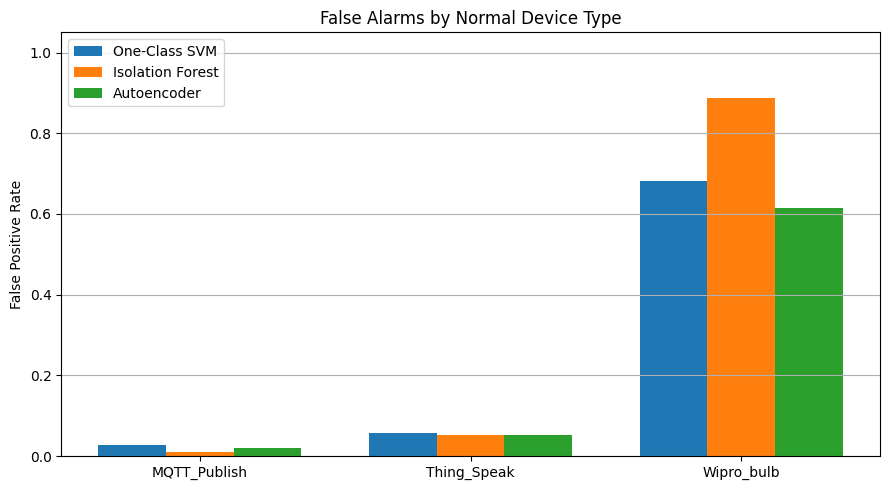

In [8]:
x = np.arange(len(false_alarm_comparison))
width = 0.25

plt.figure(figsize = (9,5))

for i, model_name in enumerate(["One-Class SVM", "Isolation Forest", "Autoencoder"]):
    plt.bar(x + (i - 1) * width, false_alarm_comparison[model_name], width, label = model_name)
    
plt.xticks(x, false_alarm_comparison["Attack_type"])
plt.ylabel("False Positive Rate")    
plt.title("False Alarms by Normal Device Type")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis = "y")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "false_alarms_by_normal_class.png", dpi = 300, bbox_inches = "tight")
plt.show()

For MQTT_Publish and Thing_Speak the false alarms are low for all models (between 1% and 6%).

Wipro_bulb is a problem for all three models: 61% (Autoencoder), 68% (One-Class SVM) and 89% (Isolation Forest) of its flows are flagged as attacks. Wipro_bulb has very few samples (about 150 in training), so the models do not learn its normal behaviour well.

This is a limit of the data, not of a single model.

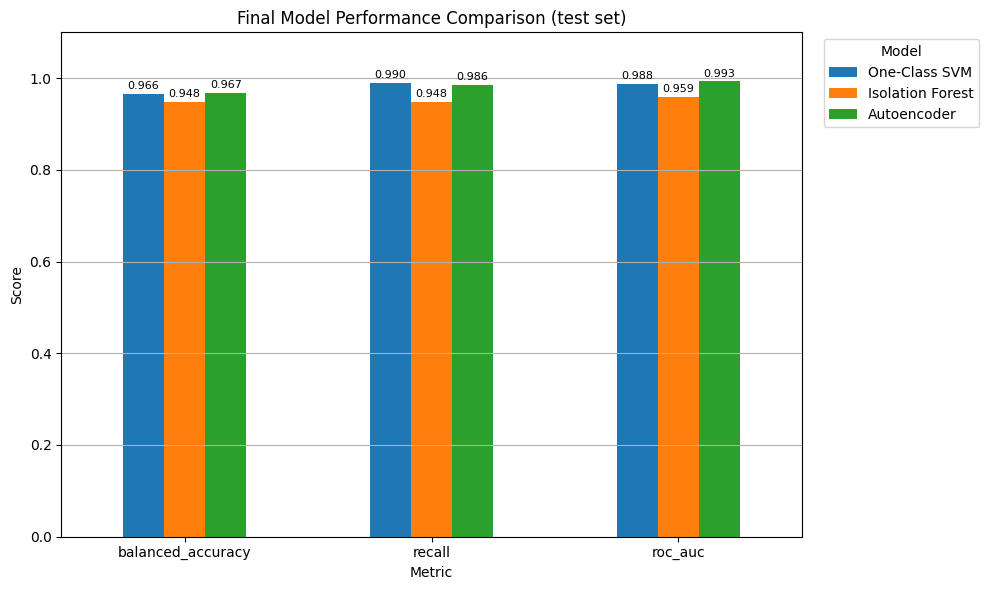

In [9]:
metrics_to_plot = ["balanced_accuracy", "recall", "roc_auc"]

plot_data = comparison_results.set_index("model")[metrics_to_plot].T

ax = plot_data.plot(kind="bar", figsize=(10, 6))

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize = 8, padding = 2)

plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("Final Model Performance Comparison (test set)")
plt.ylim(0, 1.1)
plt.xticks(rotation = 0)
plt.grid(axis = "y")
plt.legend(title = "Model", bbox_to_anchor = (1.02, 1), loc = "upper left")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "final_model_performance.png")
plt.show()

On a full scale (0-1) the three models look similar, because all of them detect most of the traffic correctly. The Isolation Forest is visibly lower in Balanced Accuracy, Recall and ROC-AUC.

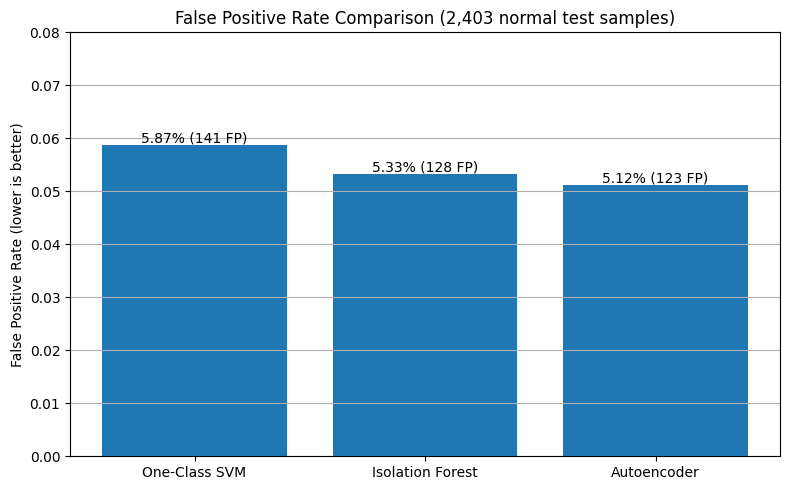

In [10]:
plt.figure(figsize = (8, 5))

bars = plt.bar(comparison_results["model"], comparison_results["fpr"])
plt.bar_label(
    bars,
    labels = [f"{fpr:.2%} ({fp} FP)" for fpr, fp in zip(comparison_results["fpr"], confusion_comparison["fp"])]
)

plt.ylabel("False Positive Rate (lower is better)")
plt.title("False Positive Rate Comparison (2,403 normal test samples)")
plt.ylim (0, 0.08)
plt.grid(axis = "y")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "false_positive_rate_comparison.png", dpi = 300, bbox_inches = "tight")
plt.show()

The False Positive Rate is about 5-6% for all models (123 to 141 false alarms out of 2403). The differences are small and, as seen with the confidence intervals, not significant.

In [11]:
attack_files = sorted(
    TABLES_DIR.glob(
        "*attack_detection*.csv"
    )
)

for file in attack_files:
    print(file.name)

autoencoder_attack_detection.csv
isolation_forest_attack_detection.csv
one_class_svm_attack_detection.csv


In [12]:
svm_attack = pd.read_csv(
    TABLES_DIR
    / "one_class_svm_attack_detection.csv"
)

if_attack = pd.read_csv(
    TABLES_DIR
    / "isolation_forest_attack_detection.csv"
)

ae_attack = pd.read_csv(
    TABLES_DIR
    / "autoencoder_attack_detection.csv"
)


print(
    "One-Class SVM:",
    svm_attack.shape
)

print(
    "Isolation Forest:",
    if_attack.shape
)

print(
  "Autoencoder:",
  ae_attack.shape  
)

One-Class SVM: (9, 4)
Isolation Forest: (9, 4)
Autoencoder: (9, 4)


In [13]:
svm_attack = (
    svm_attack[
       [
          "Attack_type",
          "detection_rate"
        ] 
    ]
    .rename(
        columns={
            "detection_rate":
            "One-Class SVM"    
        }
    )
)

if_attack = (
    if_attack[
        [
            "Attack_type",
            "detection_rate"
        ] 
    ]
    .rename(
        columns={
            "detection_rate":
            "Isolation Forest"   
        }
    )
)

ae_attack = (
    ae_attack [
        [
            "Attack_type",
            "detection_rate"    
        ]
    ]
    .rename(
        columns={
            "detection_rate":
            "Autoencoder"    
        }
    )
)

In [14]:
attack_comparison = (
    svm_attack
    .merge(
        if_attack,
        on = "Attack_type"
    )
    .merge(
        ae_attack,
        on = "Attack_type"
    )
)

attack_comparison

,Attack_type,One-Class SVM,Isolation Forest,Autoencoder
0,ARP_poisioning,0.865460,0.460530,0.801469
1,DDOS_Slowloris,1.000000,0.687970,1.000000
2,DOS_SYN_Hping,1.000000,0.987124,1.000000
3,Metasploit_Brute_Force_SSH,0.944444,0.833333,0.944444
4,NMAP_FIN_SCAN,0.928571,0.857143,0.928571
5,NMAP_OS_DETECTION,1.000000,1.000000,1.000000
6,NMAP_TCP_scan,1.000000,0.996008,1.000000
7,NMAP_UDP_SCAN,0.997678,0.991486,0.995356
8,NMAP_XMAS_TREE_SCAN,1.000000,0.999005,1.000000


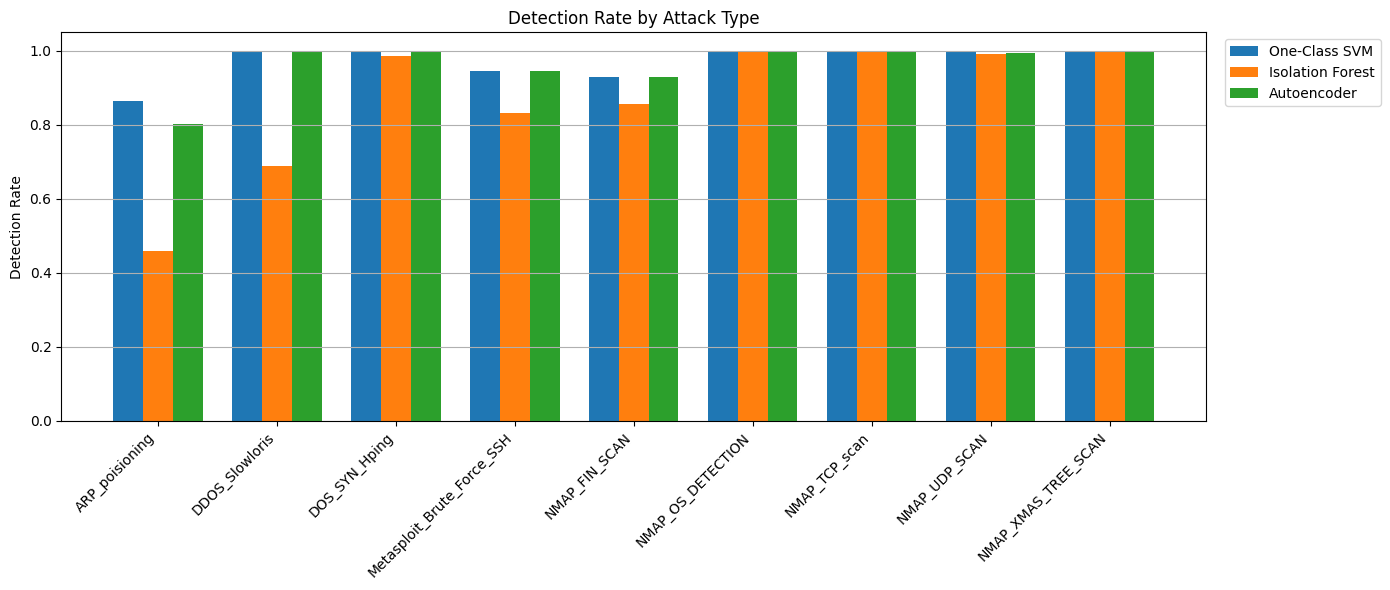

In [15]:
x = np.arange(
    len(attack_comparison)
)

width = 0.25

plt.figure(
    figsize=(14,6)
)

plt.bar(
    x - width,
    attack_comparison[
        "One-Class SVM"
    ],
    width,
    label = "One-Class SVM"
)

plt.bar(
    x,
    attack_comparison[
        "Isolation Forest"
    ],
    width,
    label = "Isolation Forest"
)

plt.bar(
    x + width,
    attack_comparison[
        "Autoencoder"
    ],
    width,
    label = "Autoencoder"
)

plt.xticks(
    x,
    attack_comparison[
        "Attack_type"
    ],
    rotation = 45,
    ha = "right"
)

plt.ylabel(
    "Detection Rate"
)

plt.title(
    "Detection Rate by Attack Type"
)

plt.ylim(
    0,
    1.05
)

plt.legend(bbox_to_anchor = (1.01, 1), loc = "upper left")

plt.grid(
    axis = "y"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "attack_detection_comparison.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()

- DOS_SYN_Hping, the NMAP scans and the small classes are detected almost perfectly by the One-Class SVM and the Autoencoder.
- **ARP_poisoning** is the hardest attack for all models: 87% (One-Class SVM), 80% (Autoencoder), 46% (Isolation Forest).
- **DDOS_Slowloris** is detected 100% by the One-Class SVM and the Autoencoder, but only 69% by the Isolation Forest.

These two attacks explain most of the gap between the Isolation Forest and the other models.

In [16]:
metric_directions = {
    "accuracy": "max", 
    "precision": "max",
    "recall":"max",
    "f1": "max",
    "balanced_accuracy": "max",
    "fpr": "min",
    "roc_auc": "max",
    "pr_auc": "max"
}

best_rows = []

for metric, direction in (
    metric_directions.items()
):
    if direction == "max":
        best_index = (
            comparison_results[
                metric
            ].idxmax()
        )
    
    else:
        best_index = (
            comparison_results[
                metric
            ].idxmin()
        )   
    
    best_rows.append(
        {
            "metric": metric,
            "best_model":
            comparison_results.loc[
                best_index,
                "model"
            ],
            "best_value":
            comparison_results.loc[
                best_index,
                metric
            ]
        }
    )

best_models = pd.DataFrame(
    best_rows
)

best_models         

,metric,best_model,best_value
0,accuracy,One-Class SVM,0.988095
1,precision,Autoencoder,0.997649
2,recall,One-Class SVM,0.990218
3,f1,One-Class SVM,0.993755
4,balanced_accuracy,Autoencoder,0.967184
5,fpr,Autoencoder,0.051186
6,roc_auc,Autoencoder,0.992868
7,pr_auc,Autoencoder,0.999650


This table shows the best model for each metric, but it must be read carefully. Accuracy, Precision and PR-AUC are not informative here, and the differences between the One-Class SVM and the Autoencoder are not significant.

So "winning" more metrics does not make a model better.

In [17]:
best_overall = comparison_ranked.iloc[0]


print(
    "Highest Balanced Accuracy:", best_overall["model"]
)

print(
    "Balanced Accuracy:",
    best_overall[
        "balanced_accuracy"
    ]
)

print(
    "Recall:",
    best_overall["recall"]
)

print(
    "False Positive Rate:",
    best_overall["fpr"]
)

Highest Balanced Accuracy: Autoencoder
Balanced Accuracy: 0.9671837408926798
Recall: 0.9855534992635118
False Positive Rate: 0.0511860174781523


In [18]:
comparison_results.to_csv(
    TABLES_DIR
    / "final_model_comparison.csv",
    index = False
)

comparison_ranked.to_csv(
    TABLES_DIR
    / "final_model_ranking.csv",
    index = False
)

confusion_comparison.to_csv(
    TABLES_DIR
    / "final_confusion_comparison.csv",
    index = False
)
attack_comparison.to_csv(
    TABLES_DIR
    / "final_attack_comparison.csv",
    index = False
)

best_models.to_csv(
    TABLES_DIR
    / "final_best_models.csv",
    index = False
)

ba_confidence.to_csv(TABLES_DIR / "final_balanced_accuracy_ci.csv", index = False)
false_alarm_comparison.to_csv(TABLES_DIR / "final_false_alarm_comparison.csv", index = False)

## Conclusions

Now concluding the project, we can definitely analyze the results obtained:

**1. Autoencoder and One-Class SVM are equivalent.**
Their Balanced Accuracy is practically the same (0.967 and 0.966) and the difference is not statistically significant. They offer a different trade-off:

- the One-Class SVM misses fewer attacks (518 against 765)
- the Autoencoder produces fewer false alarms (123 against 141)

The choice depends on what is more costly in practice: a missed attack or a false alarm.

**2. The Isolation Forest is clearly worse** (Balanced Accuracy 0.948). It misses many more attacks (2739), mostly ARP_poisoning and DDOS_Slowloris.

**3. All models share the same weak points:**

- ARP_poisoning is the hardest attack to detect.
- Wipro_bulb, a normal device with very few samples, causes many false alarms.

**Limitations**

- The results come from a single split of the data.
- The validation set contains the same attack types as the test set, so we do not measure the detection of completely new (zero-day) attacks.
- Most attacks are DOS_SYN_Hping, which is easy to detect. The ports help with it, but the One-Class SVM shows that the models do not rely only on them.

**Possible improvements** 

- collect more normal traffic for rare devices such as Wipro_bulb
- test the models on attack types never used to choose the hyperparameters.
- combine the models, for example the Autoencoder for few false alarms and the One-Class SVM for high recall.